# Netflix Movie Data

This dataset contains more than 8,500 Netflix movies and TV shows, including cast members, duration, and genre. It contains titles added as recently as late September 2021.

Not sure where to begin? Scroll to the bottom to find challenges!

In [145]:
import pandas as pd
nf = pd.read_csv("netflix_dataset.csv", index_col=0)
print(nf.shape)
nf.head(100)

(8807, 11)


,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
show_id,,,,,,,,,,,
s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...
...,...,...,...,...,...,...,...,...,...,...,...
s96,TV Show,The Circle,NaN,Michelle Buteau,"United States, United Kingdom","September 8, 2021",2021,TV-MA,3 Seasons,Reality TV,Status and strategy collide in this social exp...
s97,Movie,If I Leave Here Tomorrow: A Film About Lynyrd ...,Stephen Kijak,"Ronnie Van Zandt, Gary Rossington, Allen Colli...",United States,"September 7, 2021",2018,TV-MA,97 min,"Documentaries, Music & Musicals","Using interviews and archival footage, this do..."
s98,TV Show,Kid Cosmic,NaN,"Jack Fisher, Tom Kenny, Amanda C. Miller, Kim ...",United States,"September 7, 2021",2021,TV-Y7,2 Seasons,"Kids' TV, TV Comedies, TV Sci-Fi & Fantasy",A boy's superhero dreams come true when he fin...


[Source](https://www.kaggle.com/shivamb/netflix-shows) of dataset.

## Don't know where to start? 

**Challenges are brief tasks designed to help you practice specific skills:**

- 🗺️ **Explore**: How much variety exists in Netflix's offering? Base this on three variables: `type`, `country`, and `listed_in`.
- 📊 **Visualize**: Build a word cloud from the movie and TV shows descriptions. Make sure to remove stop words!
- 🔎 **Analyze**: Has Netflix invested more in certain genres (see `listed_in`) in recent years? What about certain age groups (see `ratings`)?

**Scenarios are broader questions to help you develop an end-to-end project for your portfolio:**

A talent agency has hired you to analyze patterns in the professional relationships of cast members and directors. The key deliverable is a network graph where each node represents a cast member or director. An edge represents a movie or TV show worked on by both nodes in this undirected graph. You can limit the actors to the first four names listed in `cast`. The client is interested in any insights you can derive from your Netflix network analysis, such as actor/actor and actor/director pairs that work most closely together, most popular actors and directors to work with, and graph differences over time.

You will need to prepare a report that is accessible to a broad audience. It will need to outline your motivation, analysis steps, findings, and conclusions.

# **Step 1: Explore the Netflix dataset**
Our first challenge is to understand the variety of content available on Netflix using three columns:
1. type – Movies and TV Shows.
2. country – Countries where content was produced.
3. listed_in – Genres and categories.

In [146]:

import matplotlib.pyplot as plt
import seaborn as sns


# **1.1 Check the dataset**
This helps us understand the dataset and identify missing information.

In [147]:

# Check dataset dimensions
print("Dataset shape:", nf.shape)

# Check column names
print("\nColumns:")
print(nf.columns.tolist())

# Check missing values
print("\nMissing values:")
print(nf[["type", "country", "listed_in"]].isnull().sum())


Dataset shape: (8807, 11)

Columns:
['type', 'title', 'director', 'cast', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in', 'description']

Missing values:
type           0
country      831
listed_in      0
dtype: int64


# **1.2 Explore content types**
Let's see how many movies and TV shows Netflix has.

type
Movie      6131
TV Show    2676
Name: count, dtype: int64


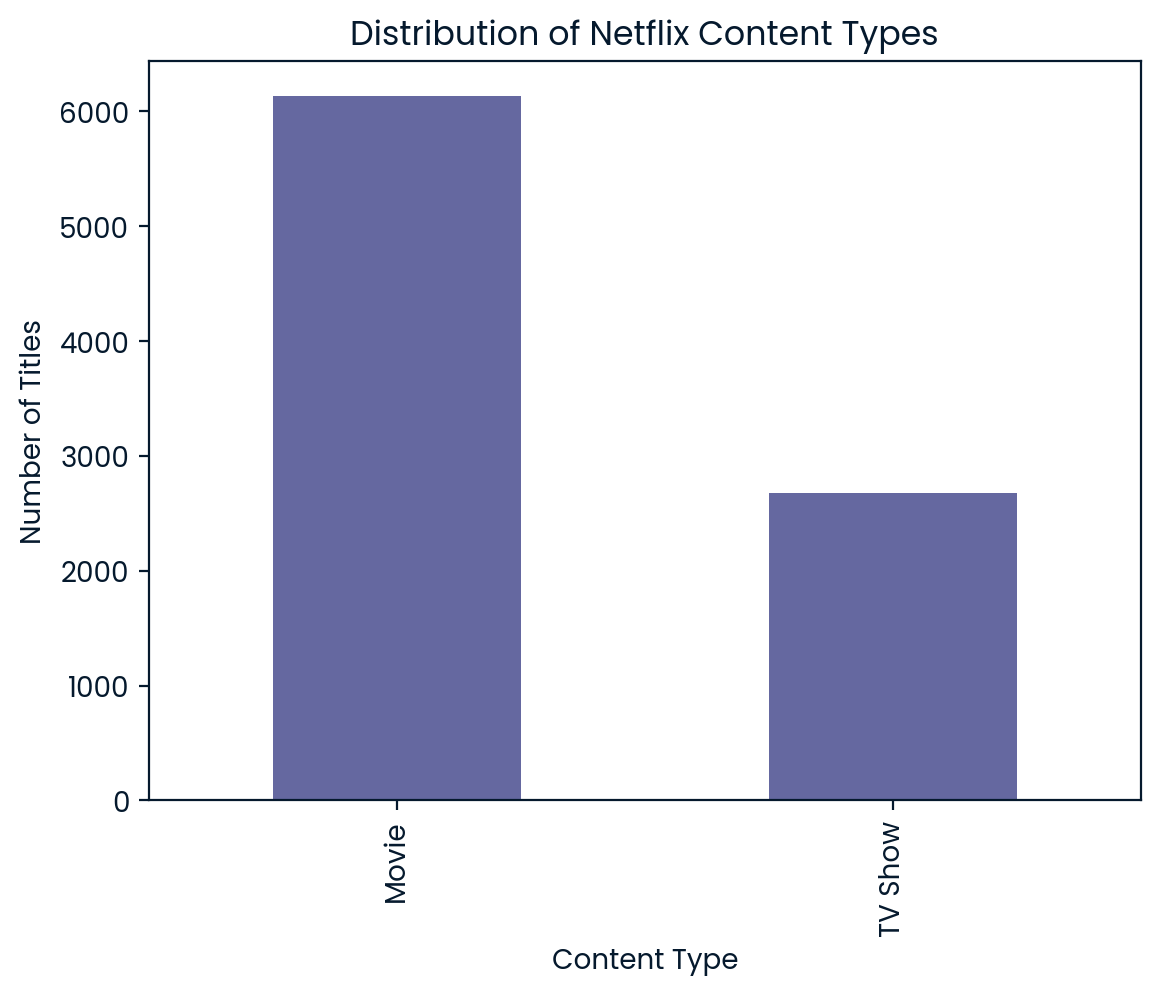

In [148]:

# Count movies and TV shows
type_counts = nf["type"].value_counts()

print(type_counts)

# Visualize the results
type_counts.plot(
    kind="bar",
    title="Distribution of Netflix Content Types",
    xlabel="Content Type",
    ylabel="Number of Titles"
)

plt.show()


# **1.3 Explore countries**
Next, let's identify the countries contributing the most content.

country
United States     3689
India             1046
United Kingdom     804
Canada             445
France             393
Japan              318
Spain              232
South Korea        231
Germany            226
Mexico             169
Name: count, dtype: int64


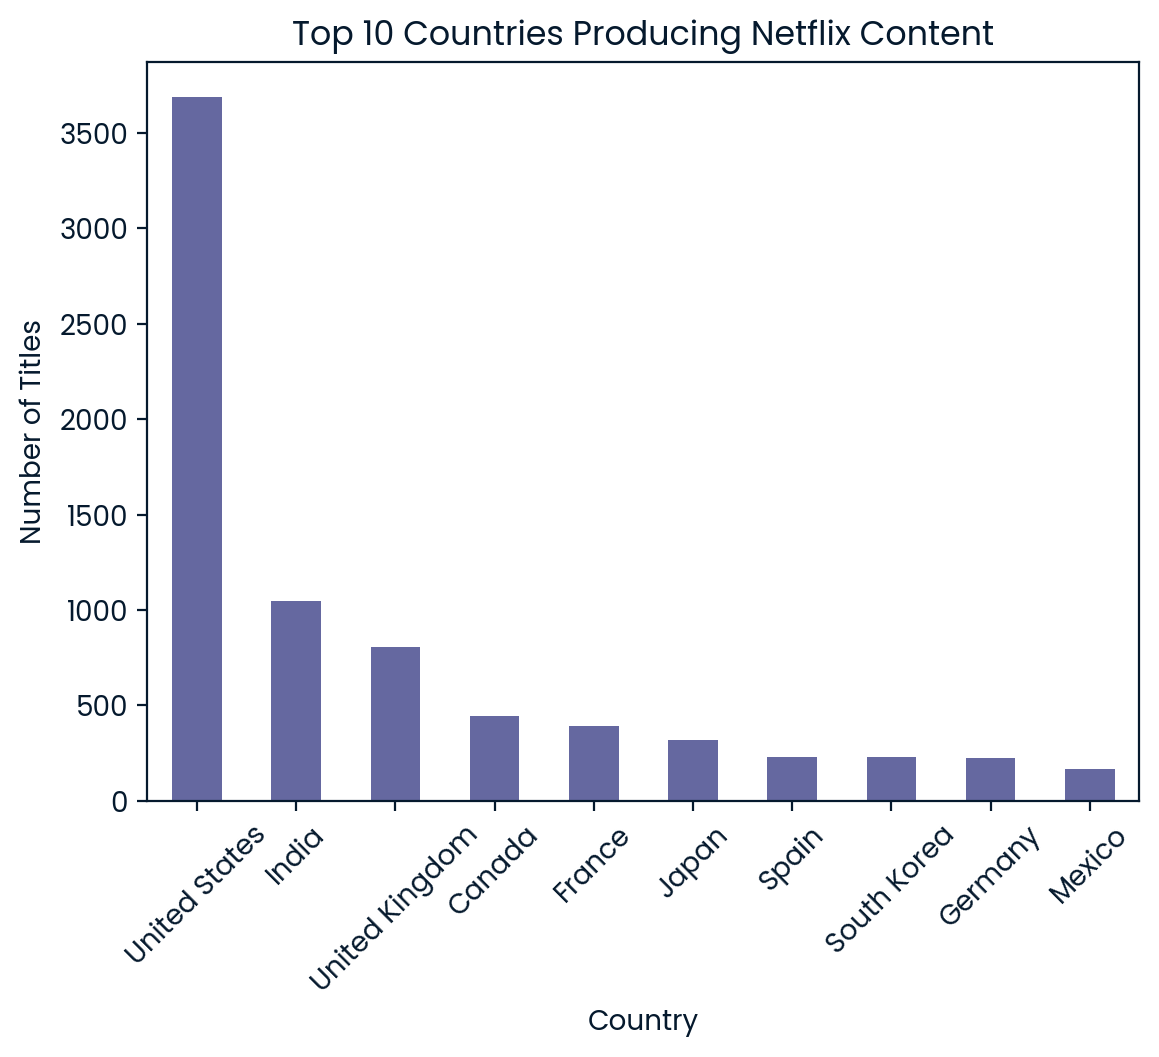

In [149]:

# Count titles by country
country_counts = nf["country"].dropna().str.split(", ").explode().value_counts()

# Display the top 10 countries
print(country_counts.head(10))

# Visualize
country_counts.head(10).plot(
    kind="bar",
    title="Top 10 Countries Producing Netflix Content",
    xlabel="Country",
    ylabel="Number of Titles"
)

plt.xticks(rotation=45)
plt.show()


listed_in
International Movies        2752
Dramas                      2427
Comedies                    1674
International TV Shows      1351
Documentaries                869
Action & Adventure           859
TV Dramas                    763
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
TV Comedies                  581
Thrillers                    577
Crime TV Shows               470
Kids' TV                     451
Docuseries                   395
Name: count, dtype: int64


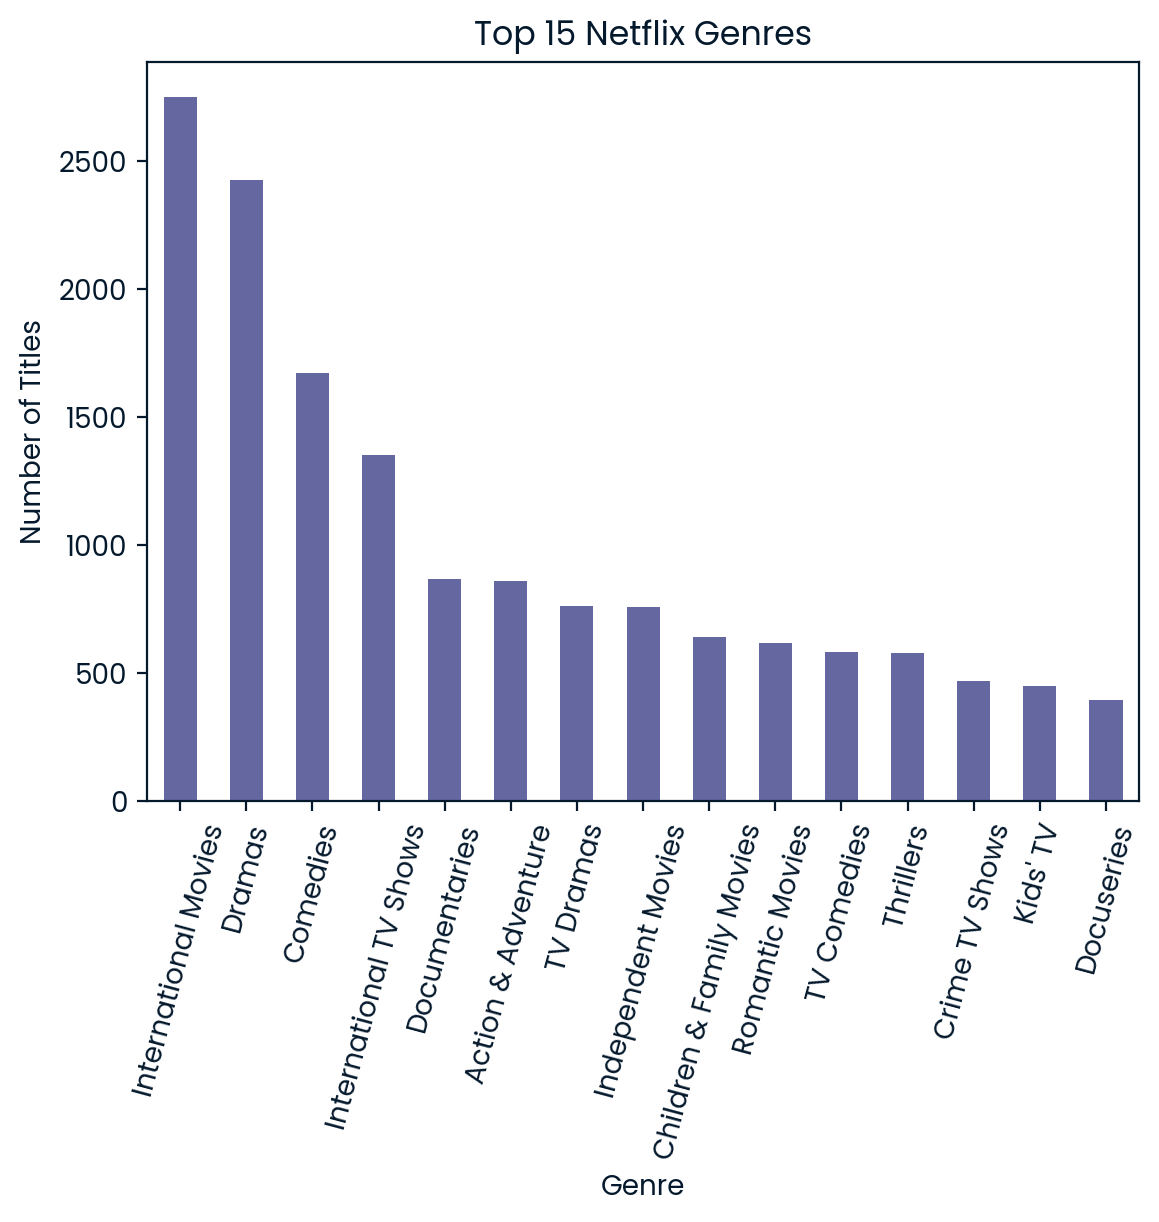

In [150]:

# Split multiple genres and count them individually
genre_counts = nf["listed_in"].dropna().str.split(", ").explode().value_counts()

# Display the top 15 genres
print(genre_counts.head(15))

# Visualize
genre_counts.head(15).plot(
    kind="bar",
    title="Top 15 Netflix Genres",
    xlabel="Genre",
    ylabel="Number of Titles"
)

plt.xticks(rotation=75)
plt.show()


# **Step 1 conclusion**
Netflix's catalogue contains 8,807 titles, consisting of 6,131 movies and 2,676 TV shows. The United States is the largest content-producing country, followed by India and the United Kingdom. International Movies, Dramas, and Comedies are the most frequently represented categories. This suggests that Netflix offers a diverse international catalogue with a strong focus on movies and drama content.

# **Step 2: Build a word cloud**
Next, we'll visualize the most frequently used words in Netflix movie and TV show descriptions.

We'll:
1. Combine all descriptions.
2. Remove common English stop words such as "the", "is", "and", and "of".
3. Generate a word cloud.
4. Display the visualization.

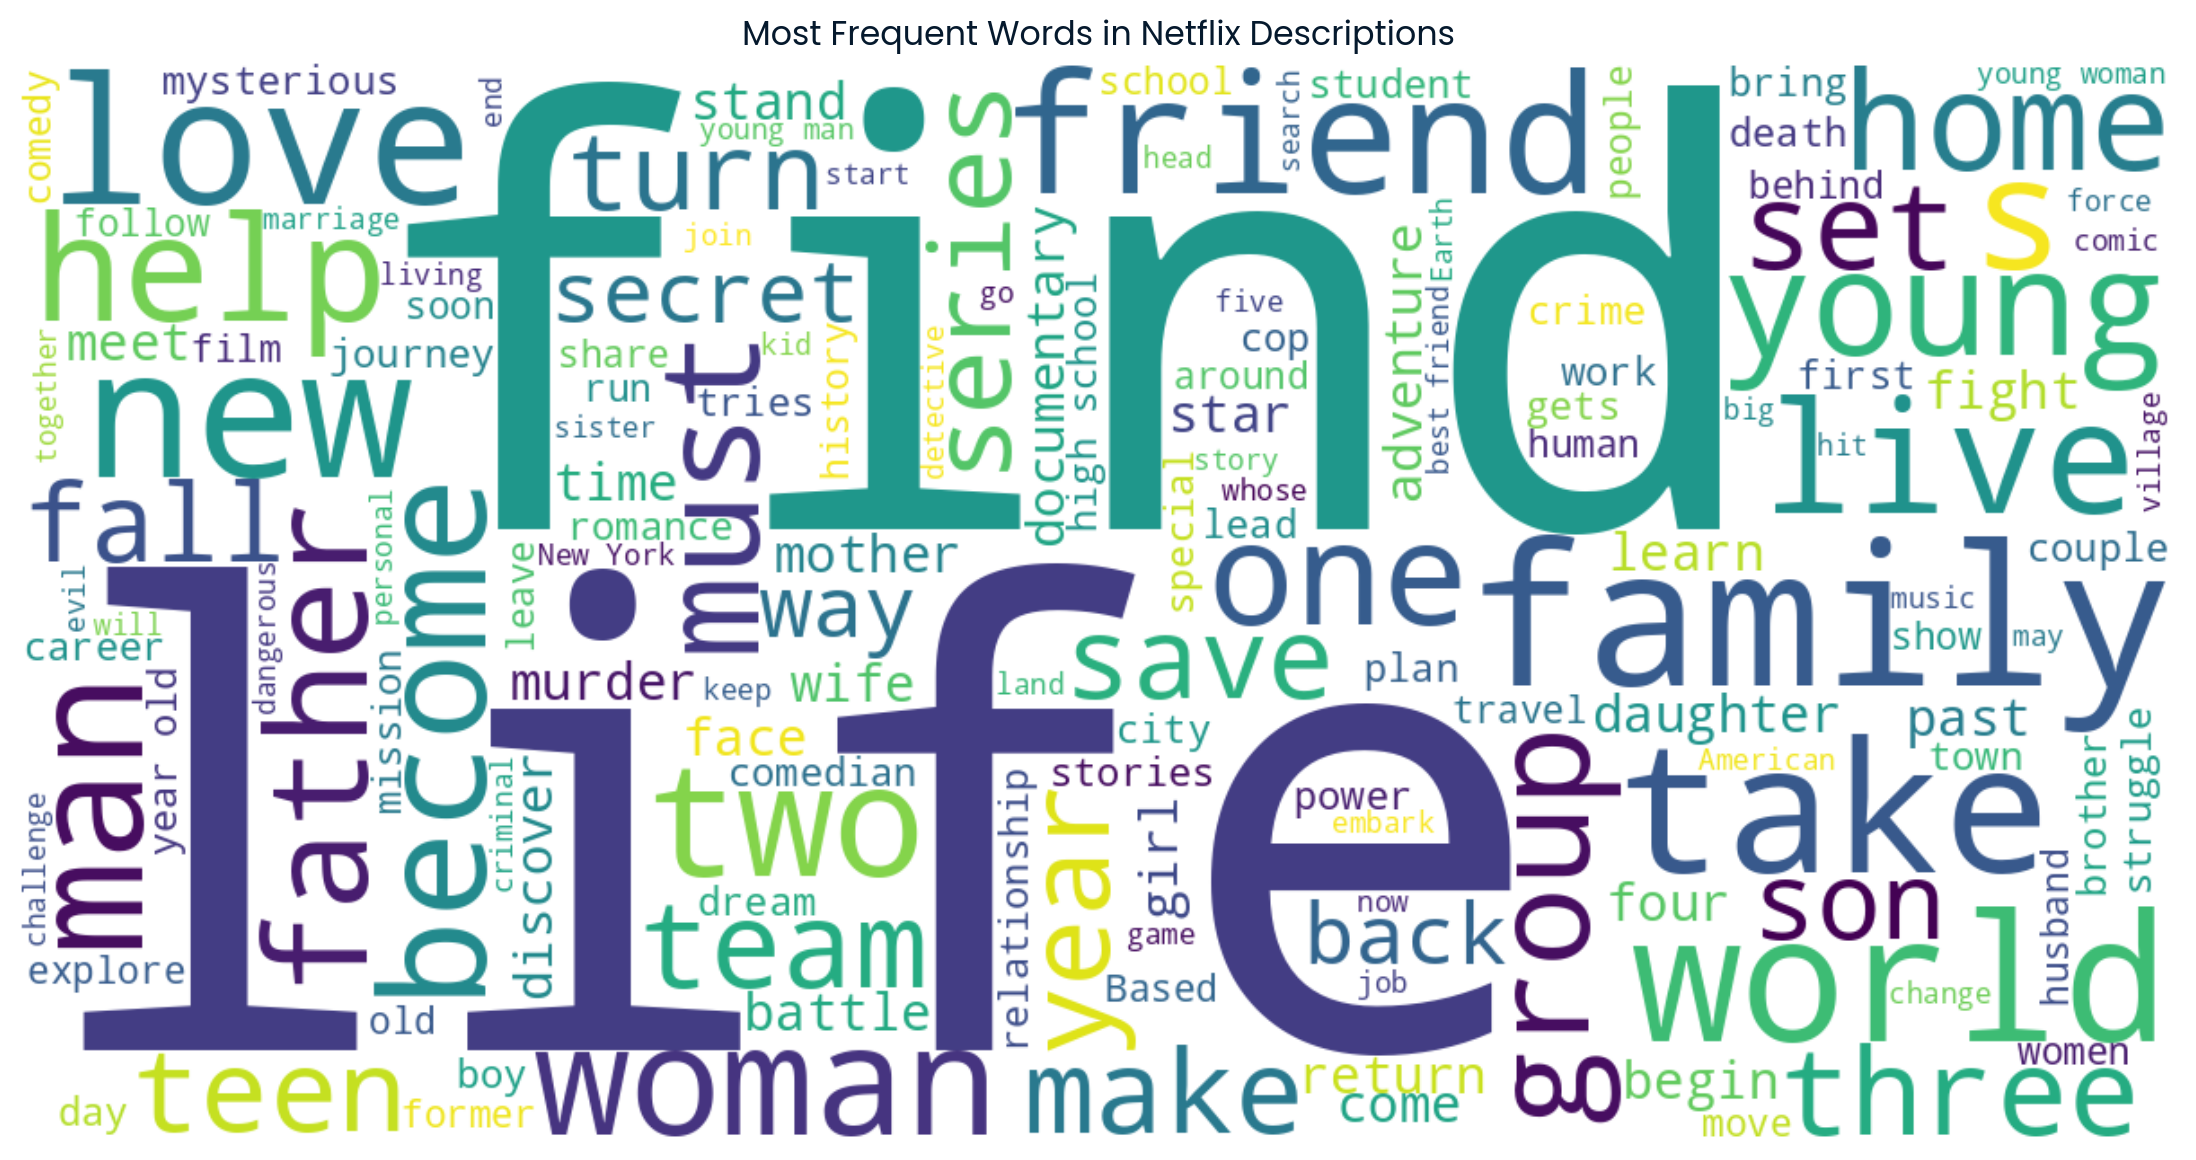

In [151]:

# Install if necessary:
# !pip install wordcloud

from wordcloud import WordCloud, STOPWORDS
import matplotlib.pyplot as plt

# Combine all descriptions into one text
text = " ".join(nf["description"].dropna().astype(str))

# Create a word cloud
wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color="white",
    stopwords=STOPWORDS,
    colormap="viridis",
    max_words=150
).generate(text)

# Display the word cloud
plt.figure(figsize=(15, 7))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Most Frequent Words in Netflix Descriptions")
plt.show()


# **Step 2: Understanding your word cloud**
The word cloud highlights the most frequently occurring words in Netflix descriptions. Larger words appear more frequently.

Some of the prominent words in your visualization are:
- life – Stories about people's lives and experiences.
- family – Family relationships and experiences.
- love – Romantic relationships and emotional stories.
- young – Stories involving young people.
- world – Stories involving different places and societies.
- man, woman, father, son – Characters and family relationships.
- time, years, new – Time-related and changing experiences.
Key insight: Netflix descriptions frequently focus on relationships, family, personal experiences, love, and life-changing events.

One important distinction: these words describe the language used in Netflix summaries, not necessarily the actual number of movies in each subject category.

# **Step 3: Analyze genre and age-rating trends**
Now we'll investigate whether Netflix has focused more on particular genres and age ratings in recent years.

We'll use:
- date_added to identify when content was added to Netflix.
- listed_in to identify genres.
- rating to identify audience classifications.

We'll focus on 2015–2021.

# **3.1 Prepare the data**

In [152]:

# Convert date_added into datetime format
nf["date_added"] = pd.to_datetime(
    nf["date_added"].str.strip(),
    errors="coerce"
)

# Extract the year content was added
nf["year_added"] = nf["date_added"].dt.year

# Check the results
print(nf[["title", "date_added", "year_added"]].head(10))

# Check available years
print("\nContent added by year:")
print(nf["year_added"].value_counts().sort_index())


                                    title date_added  year_added
show_id                                                         
s1                   Dick Johnson Is Dead 2021-09-25      2021.0
s2                          Blood & Water 2021-09-24      2021.0
s3                              Ganglands 2021-09-24      2021.0
s4                  Jailbirds New Orleans 2021-09-24      2021.0
s5                           Kota Factory 2021-09-24      2021.0
s6                          Midnight Mass 2021-09-24      2021.0
s7       My Little Pony: A New Generation 2021-09-24      2021.0
s8                                Sankofa 2021-09-24      2021.0
s9          The Great British Baking Show 2021-09-24      2021.0
s10                          The Starling 2021-09-24      2021.0

Content added by year:
year_added
2008.0       2
2009.0       2
2010.0       1
2011.0      13
2012.0       3
2013.0      11
2014.0      24
2015.0      82
2016.0     429
2017.0    1188
2018.0    1649
2019.0    2016
2020.

# **3.2 Analyze genre trends**
First, let's identify which genres were added most frequently in recent years.

Top 5 genres:
['International Movies', 'Dramas', 'Comedies', 'International TV Shows', 'Documentaries']


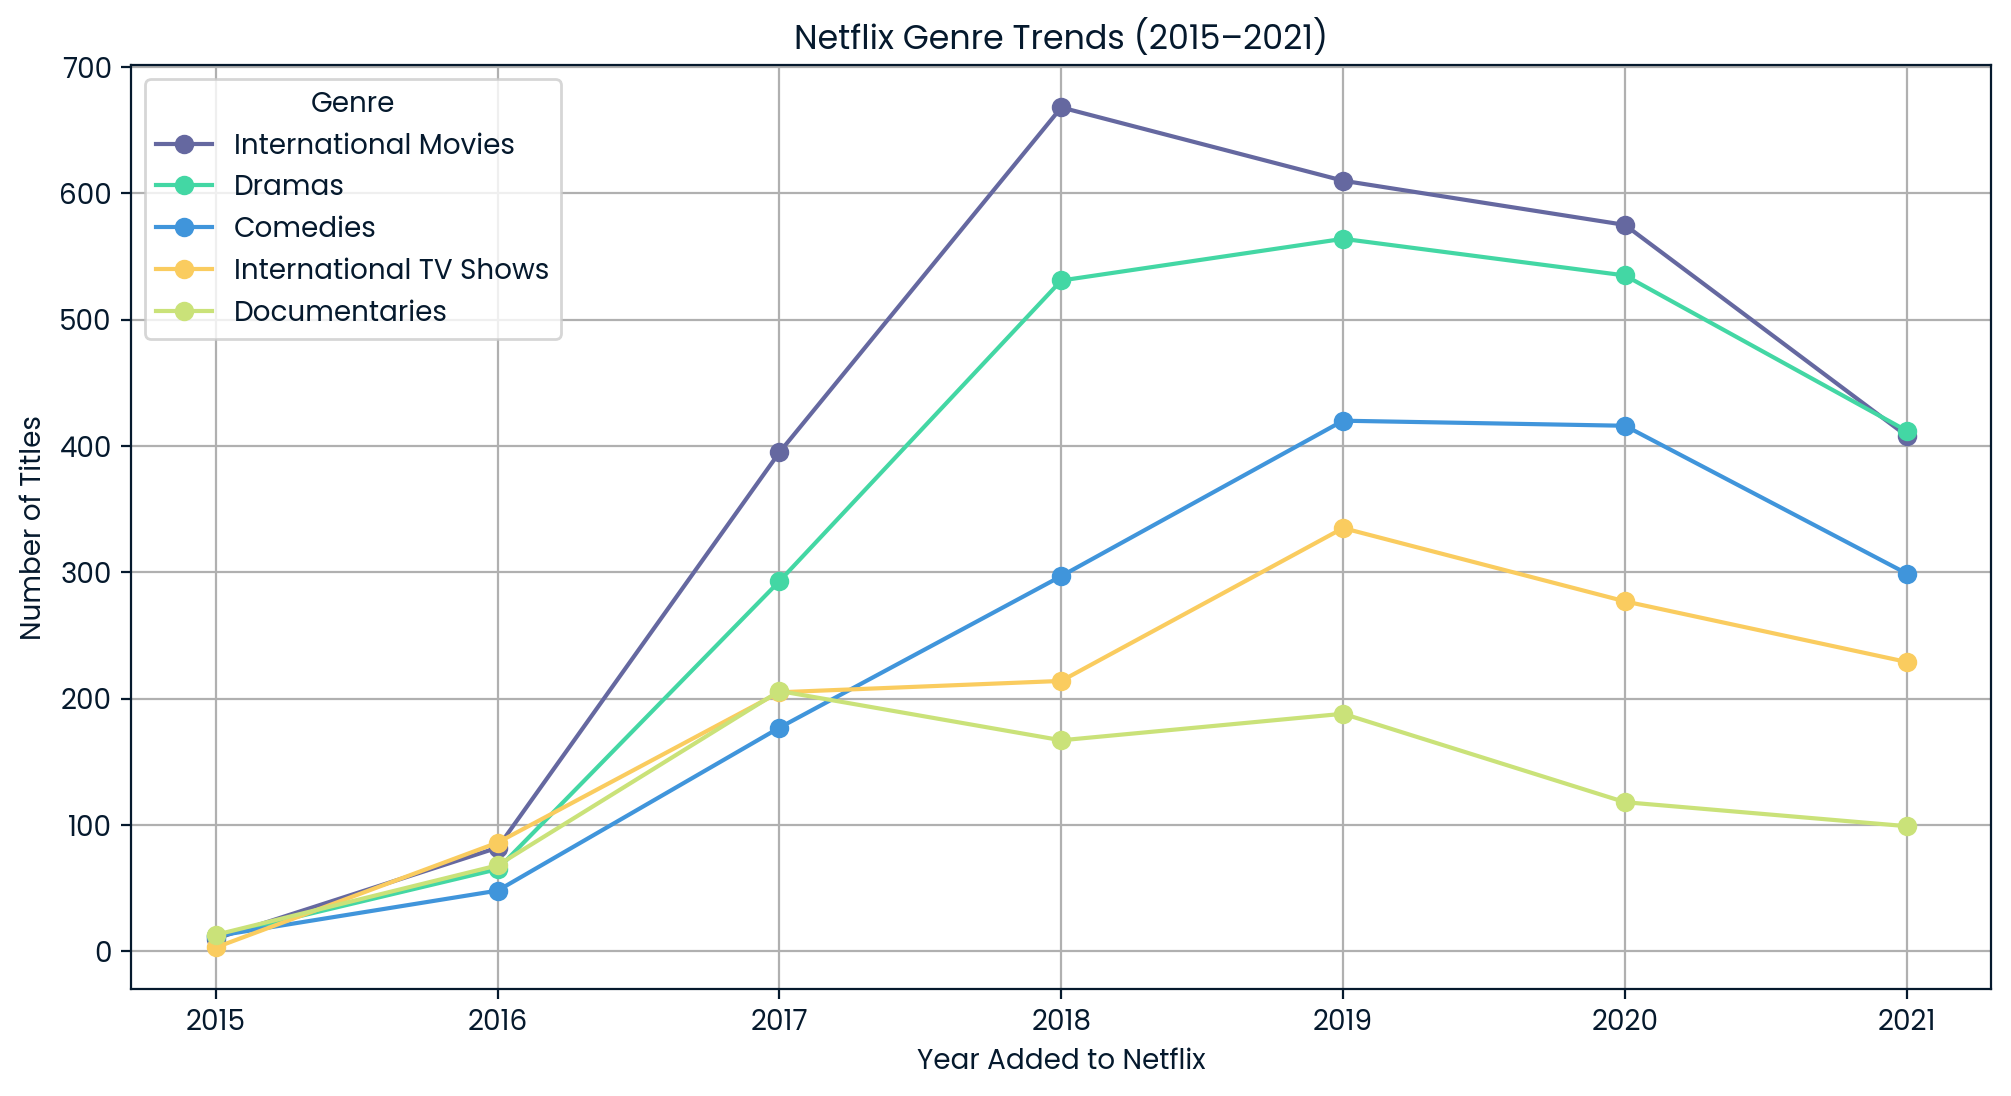

In [153]:

# Filter content added from 2015 onwards
recent = nf[nf["year_added"].between(2015, 2021)].copy()

# Split genres into individual categories
recent_genres = recent.assign(
    genre=recent["listed_in"].str.split(", ")
).explode("genre")

# Count genres by year
genre_trends = pd.crosstab(
    recent_genres["year_added"],
    recent_genres["genre"]
)

# Find the five most common genres
top_genres = genre_trends.sum().nlargest(5).index

print("Top 5 genres:")
print(top_genres.tolist())

# Plot genre trends
genre_trends[top_genres].plot(
    kind="line",
    marker="o",
    figsize=(12, 6)
)

plt.title("Netflix Genre Trends (2015–2021)")
plt.xlabel("Year Added to Netflix")
plt.ylabel("Number of Titles")
plt.legend(title="Genre")
plt.grid(True)
plt.show()


This visualization will help us identify which genres Netflix expanded most over time.

# **3.3 Analyze age-rating trends**

Netflix uses ratings such as:

Rating	General meaning:
1. G	General audiences
2. PG	Parental guidance suggested
3. PG-13	Parents strongly cautioned
4. R	Restricted
5. TV-Y	Suitable for young children
6. TV-PG	Parental guidance suggested
7. TV-14	Parents strongly cautioned
8. TV-MA	Mature audiences

Let's examine how these ratings have changed over time.

Top 5 ratings:
['TV-MA', 'TV-14', 'TV-PG', 'R', 'PG-13']


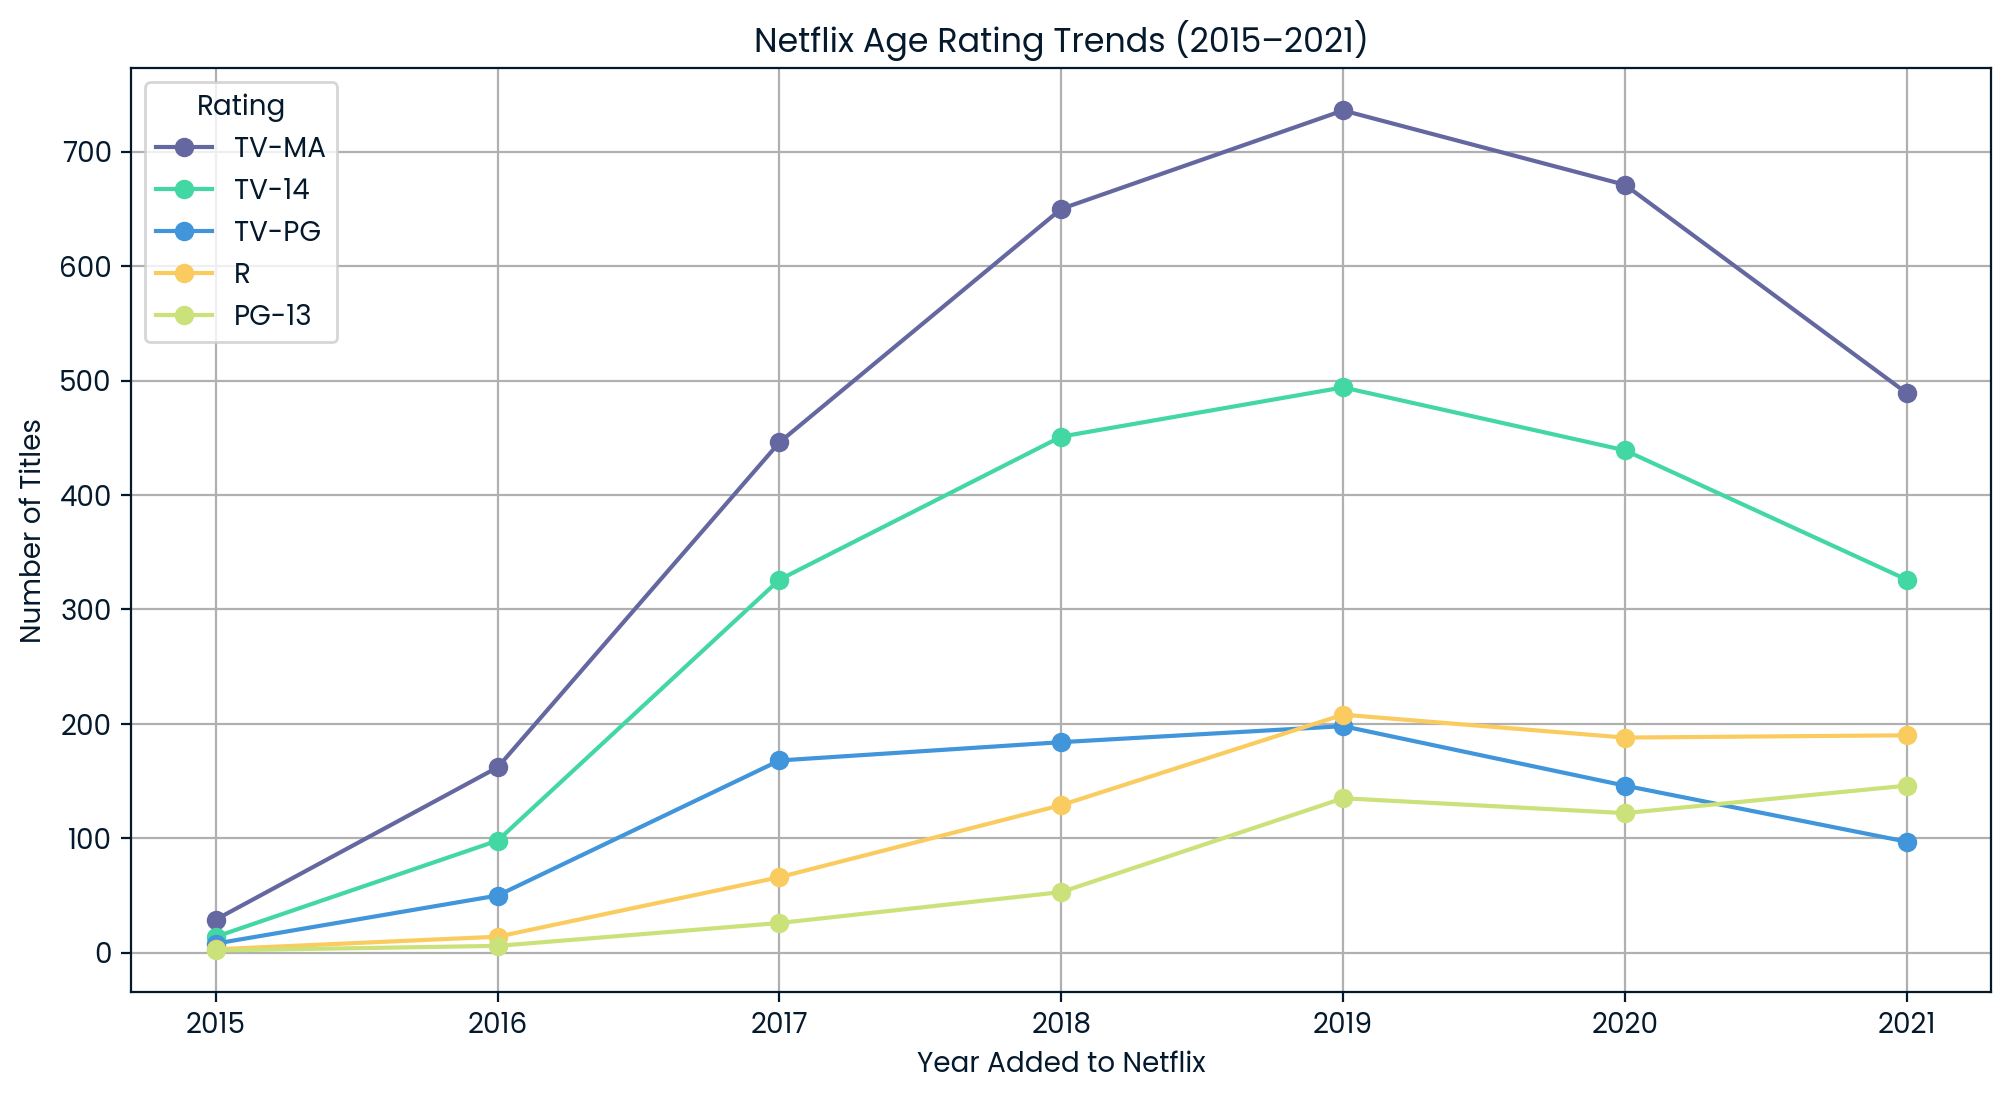

In [154]:

# Remove rows without ratings
rating_data = recent.dropna(subset=["rating"])

# Count ratings by year
rating_trends = pd.crosstab(
    rating_data["year_added"],
    rating_data["rating"]
)

# Find the five most common ratings
top_ratings = rating_trends.sum().nlargest(5).index

print("Top 5 ratings:")
print(top_ratings.tolist())

# Plot rating trends
rating_trends[top_ratings].plot(
    kind="line",
    marker="o",
    figsize=(12, 6)
)

plt.title("Netflix Age Rating Trends (2015–2021)")
plt.xlabel("Year Added to Netflix")
plt.ylabel("Number of Titles")
plt.legend(title="Rating")
plt.grid(True)
plt.show()


# **3.4 What we want to discover**
After running the code, we'll answer these questions:
1. Which genres experienced the biggest increase?
2. Did Netflix add more mature-rated content, such as TV-MA?
3. Which audience ratings were most popular?
4. Did Netflix's content strategy change between 2015 and 2021?

Important: We're measuring titles added to Netflix, not necessarily titles produced by Netflix. Also, 2021 only covers data available through late September.

# ** Step 3 conclusion **

Netflix experienced substantial growth in content additions between 2016 and 2019. International Movies, Dramas, and Comedies were among its most represented genres. In terms of audience ratings, TV-MA was the most common, followed by TV-14 and TV-PG. These findings suggest that Netflix maintained a diverse international catalogue while offering substantial content aimed at mature audiences.

# **Step 4: Netflix actor-director network analysis**

Portfolio project
Our goal is to build a network graph where:
- Each node represents an actor or director.
- An edge connects two people who worked on the same Netflix title.
- Actors are limited to the first four names in the cast column.
- We investigate the strongest professional relationships.
  
We'll use pandas, networkx, and matplotlib.

# **4.1 Install and import the required libraries**

In [155]:

# Install NetworkX if necessary
# !pip install networkx

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

from itertools import combinations

print("Libraries imported successfully!")


Libraries imported successfully!


# **4.2 Prepare the network data**
We'll extract actors and directors from each Netflix title.

In [156]:

# Create a copy of the dataset
network_df = nf.copy()

# Remove rows without cast or director information
network_df = network_df.dropna(subset=["cast", "director"])

# Extract the first four actors
network_df["actors"] = network_df["cast"].apply(
    lambda x: [name.strip() for name in x.split(",")[:4]]
)

# Extract directors
network_df["directors"] = network_df["director"].apply(
    lambda x: [name.strip() for name in x.split(",")]
)

# Display the prepared data
print(network_df[["title", "actors", "directors"]].head())


                                    title  ...                        directors
show_id                                    ...                                 
s3                              Ganglands  ...                [Julien Leclercq]
s6                          Midnight Mass  ...                  [Mike Flanagan]
s7       My Little Pony: A New Generation  ...  [Robert Cullen, José Luis Ucha]
s8                                Sankofa  ...                   [Haile Gerima]
s9          The Great British Baking Show  ...                [Andy Devonshire]

[5 rows x 3 columns]


# **4.3 Build the network graph**
This is where we connect people who worked together.

In [157]:

# Create an undirected graph
G = nx.Graph()

# Process every Netflix title
for _, row in network_df.iterrows():

    actors = ["Actor: " + name for name in row["actors"] if name]
    directors = ["Director: " + name for name in row["directors"] if name]

    # Combine all people involved in the title
    people = list(set(actors + directors))

    # Add nodes
    for person in people:
        G.add_node(person)

    # Connect everyone who worked on the same title
    for person1, person2 in combinations(people, 2):

        if G.has_edge(person1, person2):
            G[person1][person2]["weight"] += 1
        else:
            G.add_edge(person1, person2, weight=1)

print("Number of nodes:", G.number_of_nodes())
print("Number of edges:", G.number_of_edges())


Number of nodes: 17052
Number of edges: 50823


# **4.4 Visualize the network**
Let's visualize a smaller portion of the graph so that it remains readable.

# **Extract actor-director collaborations**

In [158]:

from itertools import product

# Count actor-director collaborations
collaboration_counts = {}

for _, row in network_df.iterrows():

    actors = list(set(row["actors"]))
    directors = list(set(row["directors"]))

    for actor, director in product(actors, directors):

        pair = (actor, director)

        collaboration_counts[pair] = (
            collaboration_counts.get(pair, 0) + 1
        )

# Convert results into a DataFrame
collaboration_df = pd.DataFrame([
    {
        "Actor": actor,
        "Director": director,
        "Shared Titles": count
    }
    for (actor, director), count in collaboration_counts.items()
])

# Sort by strongest collaborations
collaboration_df = collaboration_df.sort_values(
    "Shared Titles",
    ascending=False
).reset_index(drop=True)

# Display results
print("Top 15 Actor-Director Collaborations")
print(collaboration_df.head(15).to_string(index=False))

print("\nTotal collaborations:", len(collaboration_df))


Top 15 Actor-Director Collaborations
             Actor          Director  Shared Titles
      Rupa Bhimani     Rajiv Chilaka             18
     Julie Tejwani     Rajiv Chilaka             17
    Jigna Bhardwaj     Rajiv Chilaka             17
      Vatsal Dubey     Rajiv Chilaka             16
Saurav Chakraborty       Suhas Kadav              8
    Rana Daggubati    S.S. Rajamouli              7
  Kappei Yamaguchi Toshiya Shinohara              7
    Satsuki Yukino Toshiya Shinohara              7
    Koji Tsujitani Toshiya Shinohara              7
           Prabhas    S.S. Rajamouli              7
  Tamannaah Bhatia    S.S. Rajamouli              7
    Anushka Shetty    S.S. Rajamouli              7
       Omoni Oboli       Omoni Oboli              6
        Joseph May           Joey So              6
       Ata Demirer       Hakan Algül              6

Total collaborations: 21523


# **Visualize the network**

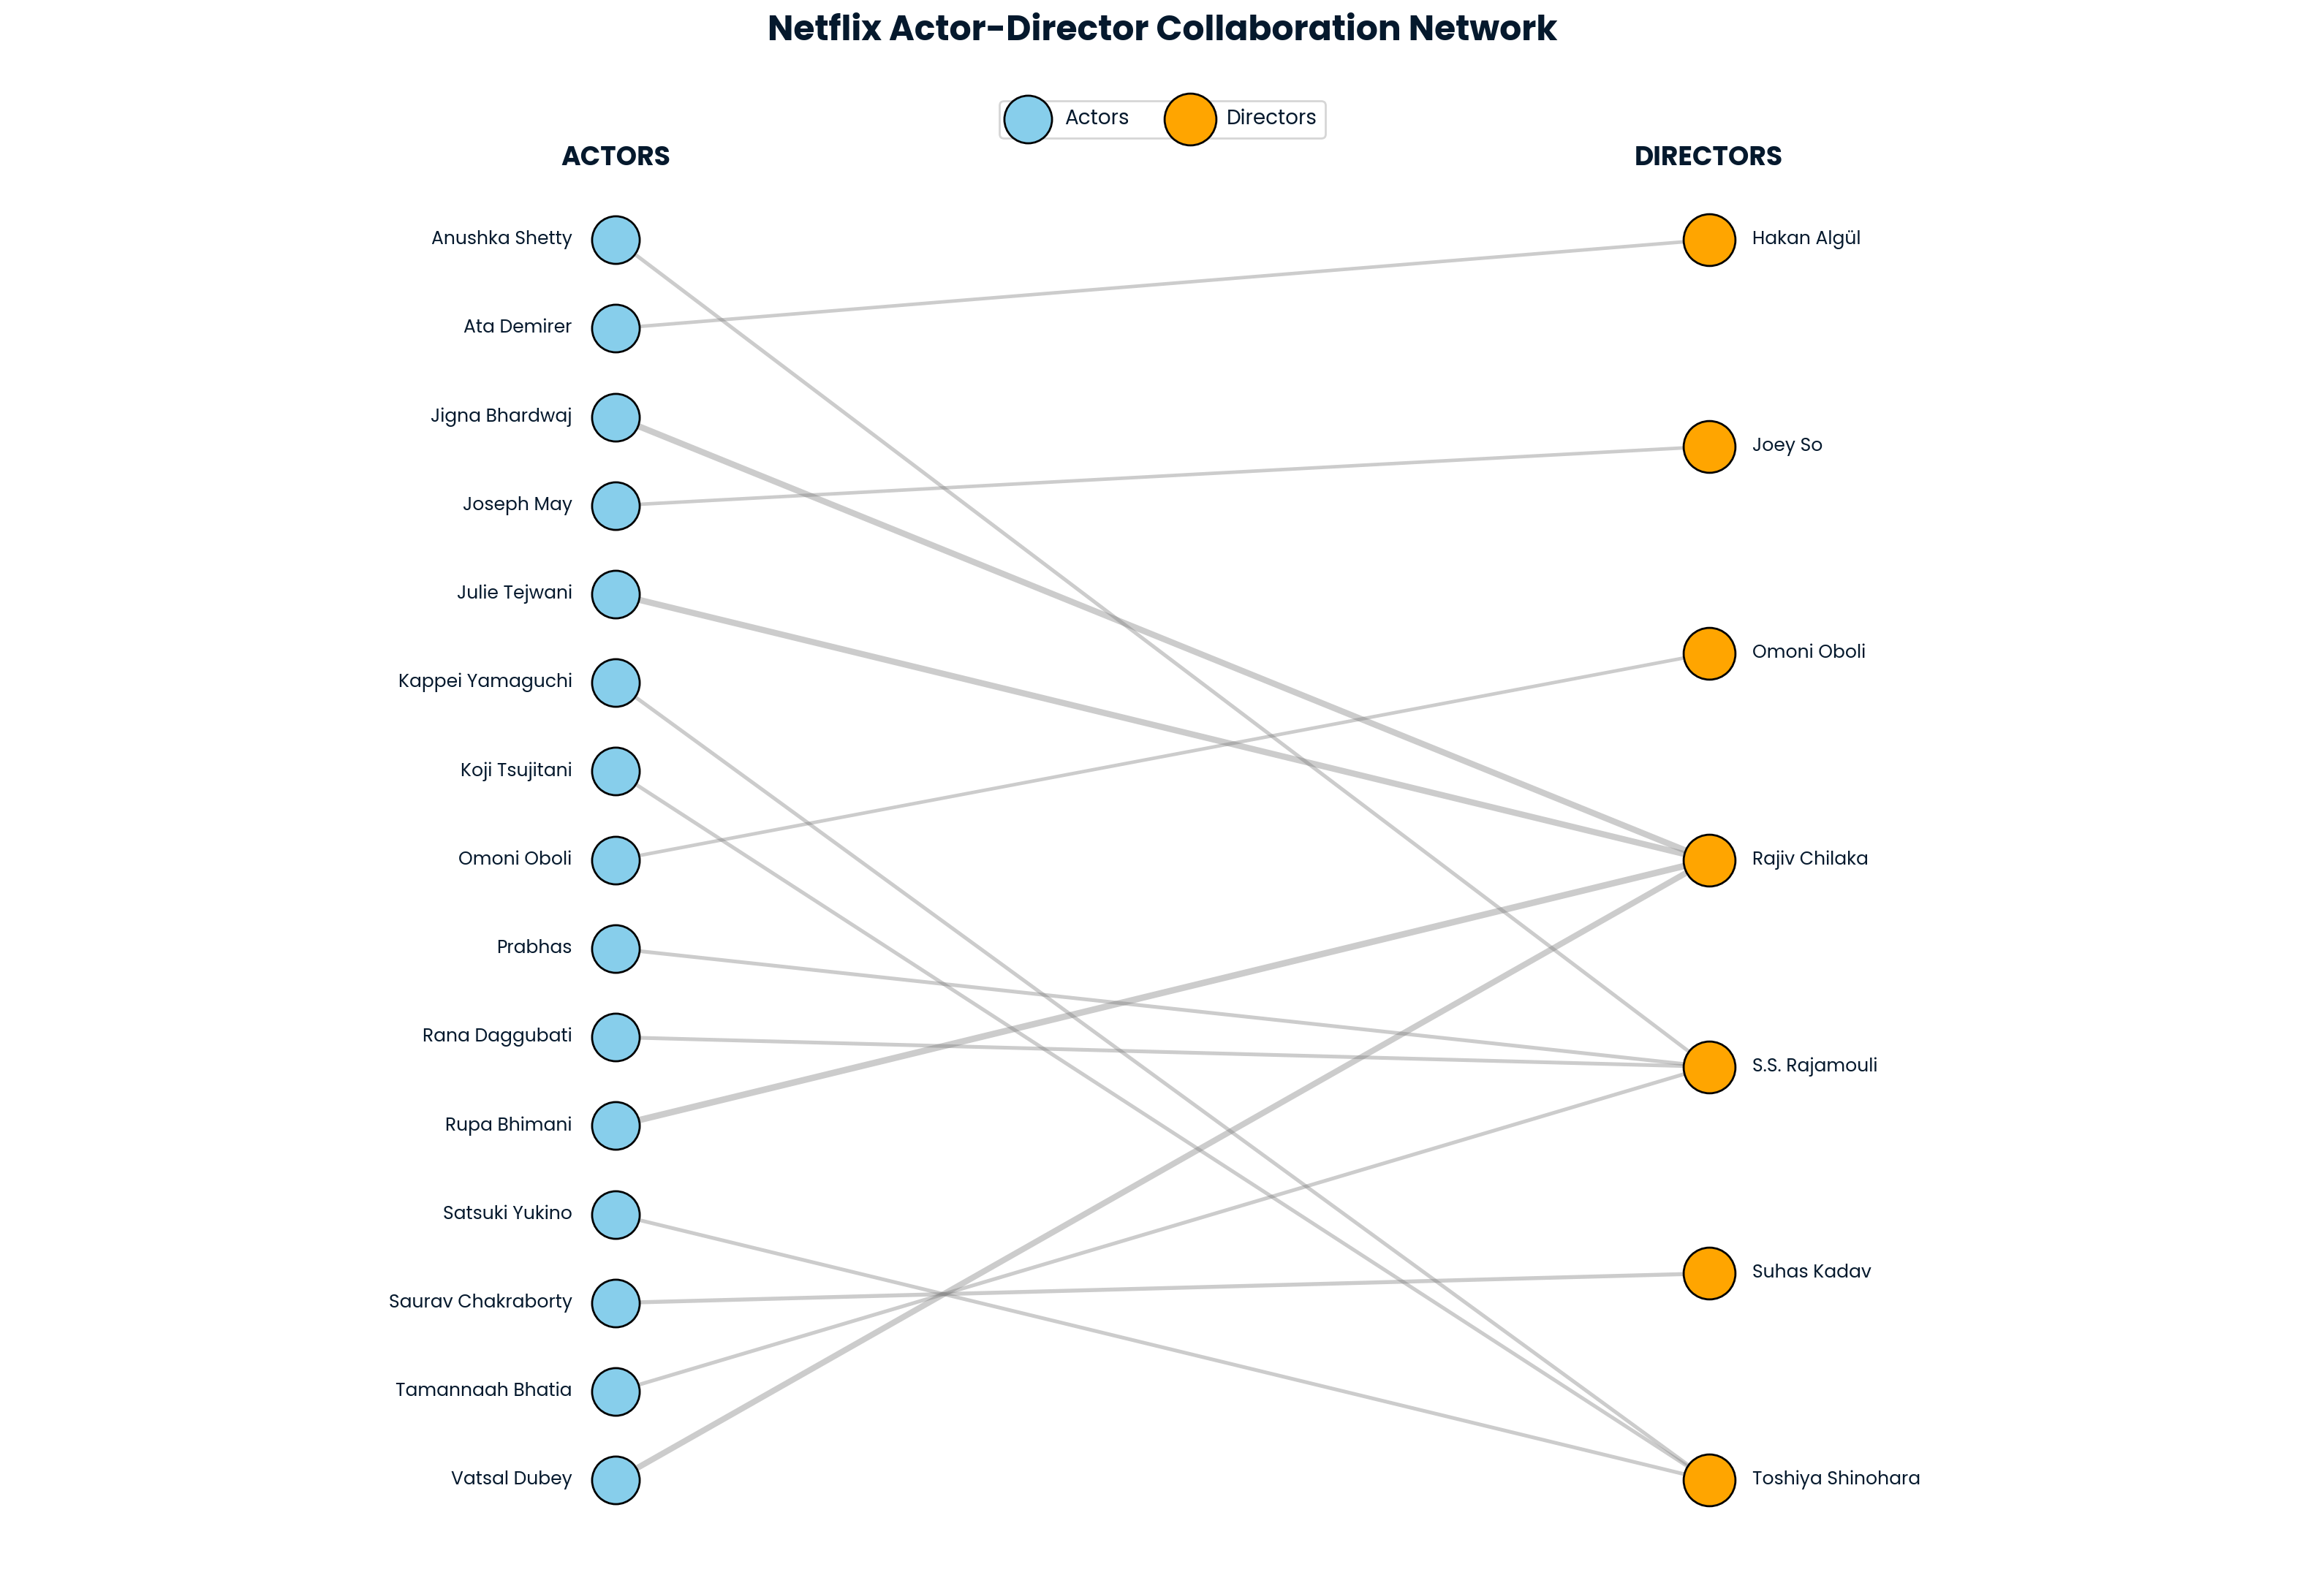

Actors displayed: 15
Directors displayed: 7
Collaborations displayed: 15


In [159]:

# Select the 15 strongest collaborations
top_collaborations = collaboration_df.head(15).copy()

# Create a bipartite graph
H = nx.Graph()

for _, row in top_collaborations.iterrows():

    actor = ("Actor", row["Actor"])
    director = ("Director", row["Director"])

    H.add_edge(
        actor,
        director,
        weight=row["Shared Titles"]
    )

# Separate actors and directors
actors = sorted(
    [n for n in H.nodes if n[0] == "Actor"],
    key=lambda n: n[1]
)

directors = sorted(
    [n for n in H.nodes if n[0] == "Director"],
    key=lambda n: n[1]
)

# Position nodes in two columns
pos = {}

for i, actor in enumerate(actors):
    pos[actor] = (0, 1 - i / max(len(actors) - 1, 1))

for i, director in enumerate(directors):
    pos[director] = (1, 1 - i / max(len(directors) - 1, 1))

# Create figure
fig, ax = plt.subplots(figsize=(16, 11))

# Draw connections
for actor, director, data in H.edges(data=True):

    ax.plot(
        [pos[actor][0], pos[director][0]],
        [pos[actor][1], pos[director][1]],
        color="gray",
        linewidth=1 + data["weight"] * 0.12,
        alpha=0.4,
        zorder=1
    )

# Draw actors
ax.scatter(
    [pos[n][0] for n in actors],
    [pos[n][1] for n in actors],
    s=550,
    color="skyblue",
    edgecolors="black",
    label="Actors",
    zorder=2
)

# Draw directors
ax.scatter(
    [pos[n][0] for n in directors],
    [pos[n][1] for n in directors],
    s=650,
    color="orange",
    edgecolors="black",
    label="Directors",
    zorder=2
)

# Actor labels
for actor in actors:
    x, y = pos[actor]
    ax.text(
        x - 0.04, y,
        actor[1],
        ha="right",
        va="center",
        fontsize=9
    )

# Director labels
for director in directors:
    x, y = pos[director]
    ax.text(
        x + 0.04, y,
        director[1],
        ha="left",
        va="center",
        fontsize=9
    )

# Headings
ax.text(0, 1.06, "ACTORS", ha="center",
        fontsize=13, fontweight="bold")

ax.text(1, 1.06, "DIRECTORS", ha="center",
        fontsize=13, fontweight="bold")

ax.set_title(
    "Netflix Actor-Director Collaboration Network",
    fontsize=17,
    fontweight="bold",
    pad=25
)

ax.set_xlim(-0.55, 1.55)
ax.set_ylim(-0.08, 1.12)

ax.legend(loc="upper center", ncol=2)
ax.axis("off")

plt.tight_layout()
plt.show()

print("Actors displayed:", len(actors))
print("Directors displayed:", len(directors))
print("Collaborations displayed:", H.number_of_edges())


In [160]:

print("Step 4.4 is executing successfully!")

print("Dataset rows:", len(network_df))
print("Prepared columns:", network_df.columns.tolist())

Step 4.4 is executing successfully!
Dataset rows: 5700
Prepared columns: ['type', 'title', 'director', 'cast', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in', 'description', 'year_added', 'actors', 'directors']


# **Step 4.5 – Check actors and directors.**
This step checks how many actor nodes and director nodes are in your complete collaboration network (G).

In [161]:

# Step 4.5: Count actors and directors in the network

actor_nodes = [
    node for node in G.nodes
    if node.startswith("Actor: ")
]

director_nodes = [
    node for node in G.nodes
    if node.startswith("Director: ")
]

print("Network Summary")
print("------------------------------")
print("Total actors:", len(actor_nodes))
print("Total directors:", len(director_nodes))
print("Total nodes:", G.number_of_nodes())
print("Total edges:", G.number_of_edges())


Network Summary
------------------------------
Total actors: 12523
Total directors: 4529
Total nodes: 17052
Total edges: 50823


# **4.6 Analyze actor-actor collaborations**
The client wants to know which actors frequently work together. We'll count how many Netflix titles each pair of actors shares.

In [162]:

# Step 4.6: Analyze actor-actor collaborations

from itertools import combinations

actor_pair_counts = {}

for _, row in network_df.iterrows():

    actors = sorted(set(row["actors"]))

    for actor1, actor2 in combinations(actors, 2):

        pair = (actor1, actor2)

        actor_pair_counts[pair] = (
            actor_pair_counts.get(pair, 0) + 1
        )

# Convert results into a DataFrame
actor_collaboration_df = pd.DataFrame([
    {
        "Actor 1": actor1,
        "Actor 2": actor2,
        "Shared Titles": count
    }
    for (actor1, actor2), count in actor_pair_counts.items()
])

# Sort by strongest collaborations
actor_collaboration_df = actor_collaboration_df.sort_values(
    "Shared Titles",
    ascending=False
).reset_index(drop=True)

print("Top 15 Actor-Actor Collaborations")
print(actor_collaboration_df.head(15).to_string(index=False))

print("\nTotal unique actor pairs:", len(actor_collaboration_df))


Top 15 Actor-Actor Collaborations
           Actor 1            Actor 2  Shared Titles
     Julie Tejwani       Rupa Bhimani             26
     Julie Tejwani       Vatsal Dubey             16
    Jigna Bhardwaj      Julie Tejwani             16
    Jigna Bhardwaj       Rupa Bhimani             16
    Jigna Bhardwaj       Vatsal Dubey             16
      Rupa Bhimani       Vatsal Dubey             16
John Paul Tremblay         Robb Wells             11
     Chie Nakamura     Junko Takeuchi             10
    Daniel Padilla   Kathryn Bernardo              8
        Mike Smith         Robb Wells              8
    John Dunsworth John Paul Tremblay              8
John Paul Tremblay         Mike Smith              8
    John Dunsworth         Robb Wells              8
           Prabhas     Rana Daggubati              7
      Rupa Bhimani       Sabina Malik              7

Total unique actor pairs: 28185


# **Step 4.7 – Identify the most frequently appearing actors and directors**
Here we identify the actors and directors who appear in the greatest number of titles.

In [163]:

# Step 4.7: Most frequently appearing actors and directors

from collections import Counter

actor_counts = Counter()
director_counts = Counter()

for _, row in network_df.iterrows():
    actor_counts.update(set(row["actors"]))
    director_counts.update(set(row["directors"]))

# Top 15 actors
top_actors_df = pd.DataFrame(
    actor_counts.most_common(15),
    columns=["Actor", "Number of Titles"]
)

# Top 15 directors
top_directors_df = pd.DataFrame(
    director_counts.most_common(15),
    columns=["Director", "Number of Titles"]
)

print("Top 15 Most Frequently Appearing Actors")
display(top_actors_df)

print("\nTop 15 Most Frequently Appearing Directors")
display(top_directors_df)


Top 15 Most Frequently Appearing Actors


,Actor,Number of Titles
0,Shah Rukh Khan,35
1,Akshay Kumar,28
2,Rupa Bhimani,27
3,Julie Tejwani,26
4,Amitabh Bachchan,25
5,Anupam Kher,22
6,Kareena Kapoor,22
7,Naseeruddin Shah,21
8,Adam Sandler,20
9,Ajay Devgn,20



Top 15 Most Frequently Appearing Directors


,Director,Number of Titles
0,Jan Suter,21
1,Rajiv Chilaka,19
2,Raúl Campos,19
3,Marcus Raboy,16
4,Jay Karas,15
5,Suhas Kadav,13
6,Cathy Garcia-Molina,13
7,Youssef Chahine,12
8,Martin Scorsese,12
9,Jay Chapman,12


In [164]:
print("TOP 15 ACTORS")
print(top_actors_df.to_string(index=False))

print("\nTOP 15 DIRECTORS")
print(top_directors_df.to_string(index=False))

TOP 15 ACTORS
              Actor  Number of Titles
     Shah Rukh Khan                35
       Akshay Kumar                28
       Rupa Bhimani                27
      Julie Tejwani                26
   Amitabh Bachchan                25
        Anupam Kher                22
     Kareena Kapoor                22
   Naseeruddin Shah                21
       Adam Sandler                20
         Ajay Devgn                20
  Samuel L. Jackson                18
     Jigna Bhardwaj                18
      Kay Kay Menon                18
Nawazuddin Siddiqui                18
            Om Puri                18

TOP 15 DIRECTORS
           Director  Number of Titles
          Jan Suter                21
      Rajiv Chilaka                19
        Raúl Campos                19
       Marcus Raboy                16
          Jay Karas                15
        Suhas Kadav                13
Cathy Garcia-Molina                13
    Youssef Chahine                12
    Martin Scorses

# **Step 4.8 – Compare network patterns over time**
The portfolio scenario specifically asks us to investigate how professional relationships differ over time.

We'll use release_year because it tells us when a title was released, which is more meaningful for studying when collaborations occurred than when Netflix added the title.

In [165]:

# Step 4.8: Compare collaboration networks over time

from itertools import combinations

# Remove records without a valid release year
time_df = network_df.dropna(subset=["release_year"]).copy()

time_df["release_year"] = pd.to_numeric(
    time_df["release_year"], errors="coerce"
)

time_df = time_df.dropna(subset=["release_year"])

# Group titles into decades
time_df["Decade"] = (
    (time_df["release_year"] // 10) * 10
).astype(int)

network_results = []

for decade, group in time_df.groupby("Decade"):

    decade_graph = nx.Graph()

    for _, row in group.iterrows():

        actors = [
            "Actor: " + name
            for name in set(row["actors"])
            if name
        ]

        directors = [
            "Director: " + name
            for name in set(row["directors"])
            if name
        ]

        people = list(set(actors + directors))

        decade_graph.add_nodes_from(people)

        for person1, person2 in combinations(people, 2):
            if decade_graph.has_edge(person1, person2):
                decade_graph[person1][person2]["weight"] += 1
            else:
                decade_graph.add_edge(
                    person1, person2, weight=1
                )

    network_results.append({
        "Decade": f"{decade}s",
        "Titles": len(group),
        "People (Nodes)": decade_graph.number_of_nodes(),
        "Connections (Edges)": decade_graph.number_of_edges()
    })

decade_df = pd.DataFrame(network_results)

print("Netflix Collaboration Network by Release Decade")
display(decade_df)


Netflix Collaboration Network by Release Decade


,Decade,Titles,People (Nodes),Connections (Edges)
0,1940s,5,16,31
1,1950s,11,48,108
2,1960s,23,107,233
3,1970s,63,273,609
4,1980s,121,488,1119
5,1990s,237,916,2227
6,2000s,673,2317,6551
7,2010s,3812,12439,33723
8,2020s,755,3217,6926


# **4.9 Collaboration intensity**
Let's compare the number of unique connections with the number of titles in each decade. This helps us avoid interpreting network growth as increased collaboration without considering dataset size.

In [166]:

# Step 4.9: Compare connections per title

decade_df["Connections per Title"] = (
    decade_df["Connections (Edges)"] / decade_df["Titles"]
).round(2)

print("Collaboration Intensity by Decade")
display(decade_df)


Collaboration Intensity by Decade


,Decade,Titles,People (Nodes),Connections (Edges),Connections per Title
0,1940s,5,16,31,6.20
1,1950s,11,48,108,9.82
2,1960s,23,107,233,10.13
3,1970s,63,273,609,9.67
4,1980s,121,488,1119,9.25
5,1990s,237,916,2227,9.40
6,2000s,673,2317,6551,9.73
7,2010s,3812,12439,33723,8.85
8,2020s,755,3217,6926,9.17


# ** Step 4.10: Calculate weighted collaboration frequency by decade**
This give a better understanding of how frequently people worked together, including repeated partnerships.

In [167]:

# Step 4.10: Calculate weighted collaboration frequency by decade

weighted_results = []

for decade, group in time_df.groupby("Decade"):

    decade_graph = nx.Graph()

    for _, row in group.iterrows():

        actors = [
            "Actor: " + name
            for name in set(row["actors"]) if name
        ]

        directors = [
            "Director: " + name
            for name in set(row["directors"]) if name
        ]

        people = list(set(actors + directors))

        decade_graph.add_nodes_from(people)

        for person1, person2 in combinations(people, 2):

            if decade_graph.has_edge(person1, person2):
                decade_graph[person1][person2]["weight"] += 1
            else:
                decade_graph.add_edge(
                    person1, person2, weight=1
                )

    total_collaborations = sum(
        data["weight"]
        for _, _, data in decade_graph.edges(data=True)
    )

    weighted_results.append({
        "Decade": f"{decade}s",
        "Titles": len(group),
        "Unique Connections": decade_graph.number_of_edges(),
        "Total Collaboration Occurrences": total_collaborations,
        "Occurrences per Title": round(
            total_collaborations / len(group), 2
        )
    })

weighted_decade_df = pd.DataFrame(weighted_results)

print("Weighted Collaboration Analysis by Decade")
print(weighted_decade_df.to_string(index=False))


Weighted Collaboration Analysis by Decade
Decade  Titles  Unique Connections  Total Collaboration Occurrences  Occurrences per Title
 1940s       5                  31                               31                   6.20
 1950s      11                 108                              115                  10.45
 1960s      23                 233                              235                  10.22
 1970s      63                 609                              633                  10.05
 1980s     121                1119                             1210                  10.00
 1990s     237                2227                             2302                   9.71
 2000s     673                6551                             6893                  10.24
 2010s    3812               33723                            35244                   9.25
 2020s     755                6926                             7149                   9.47
